In [65]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score
import joblib

In [48]:
######################################################################################
###### Tâche 1.1 : Analyse exploratoire des données (EDA) & Statistiques descriptives.
######################################################################################

# 1. Chargement du dataset
df = pd.read_csv("Data/student_mental_health.csv")
print("dimention")
print(df.shape)

# 2. Structure et types
df.info()

dimention
(2000, 17)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate         

In [49]:
# 3. Manquants et doublons
print("Les valeurs manquants")
print(df.isnull().sum())



Les valeurs manquants
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [50]:
print("Les valeurs doublents")
print(df.duplicated().sum())

Les valeurs doublents
0


In [51]:
# # 4. Statistiques des variables
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [72]:
print(df["Mental_Health_Risk"].value_counts())

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


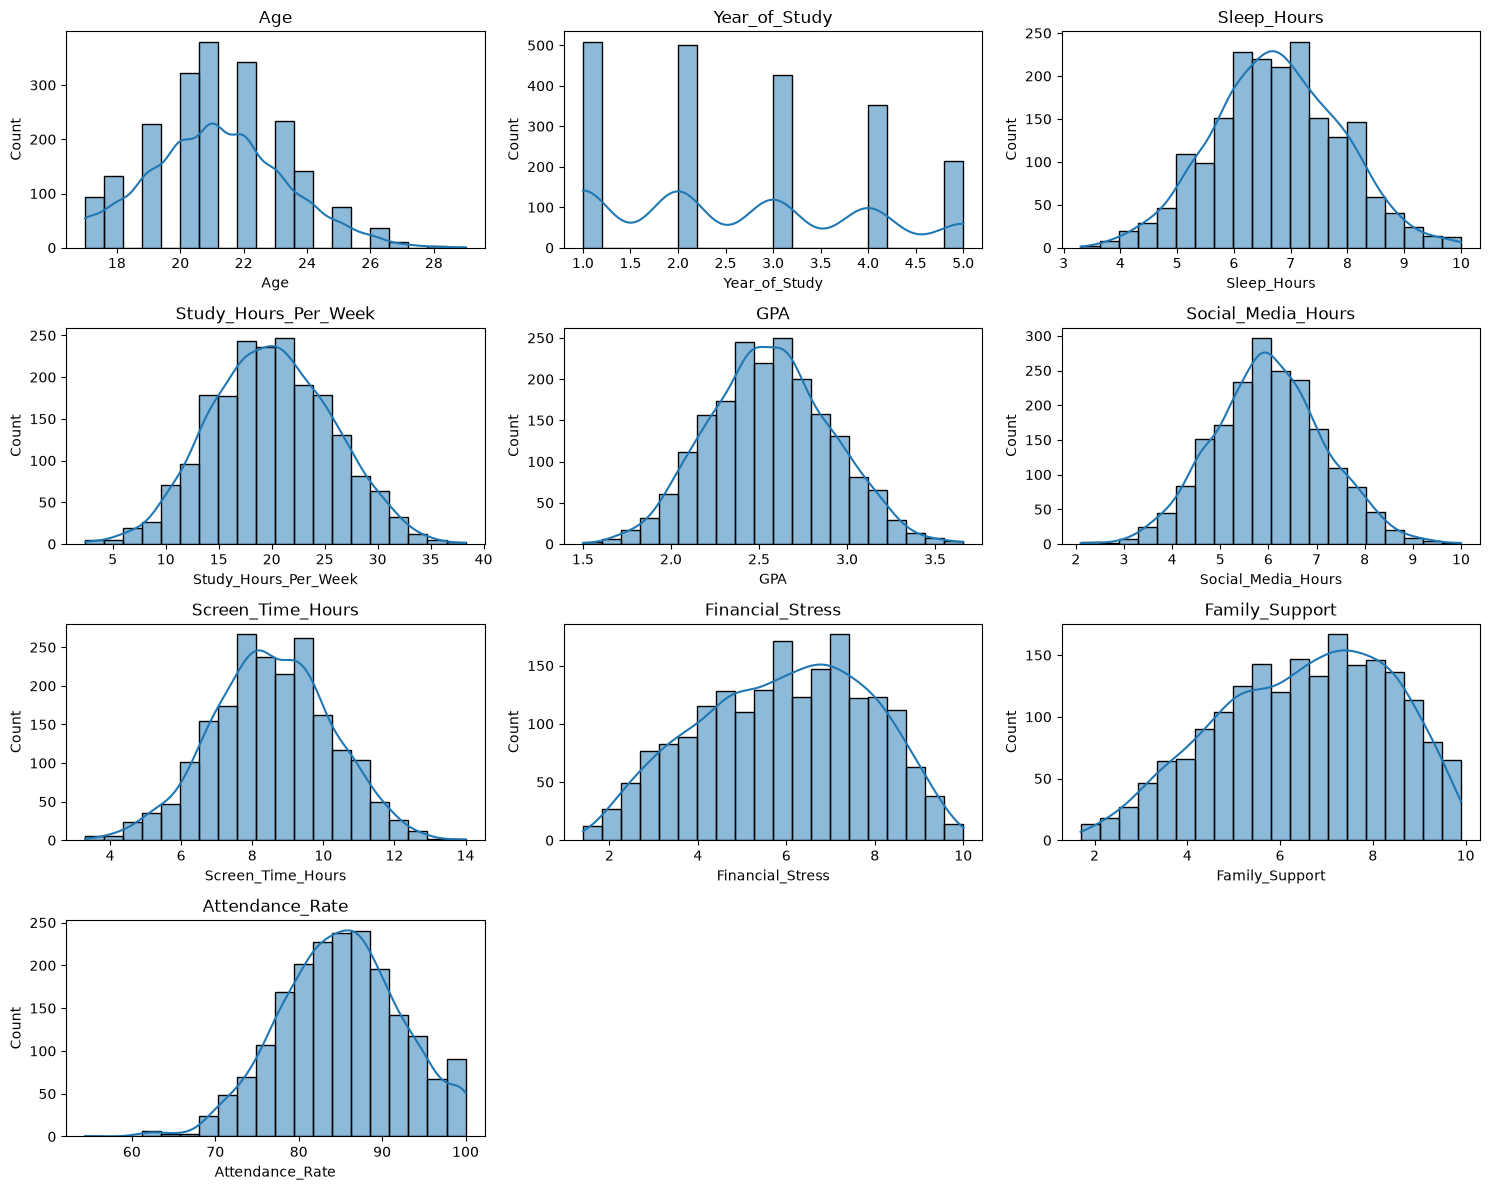

In [53]:

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(col)

plt.tight_layout()
plt.show()

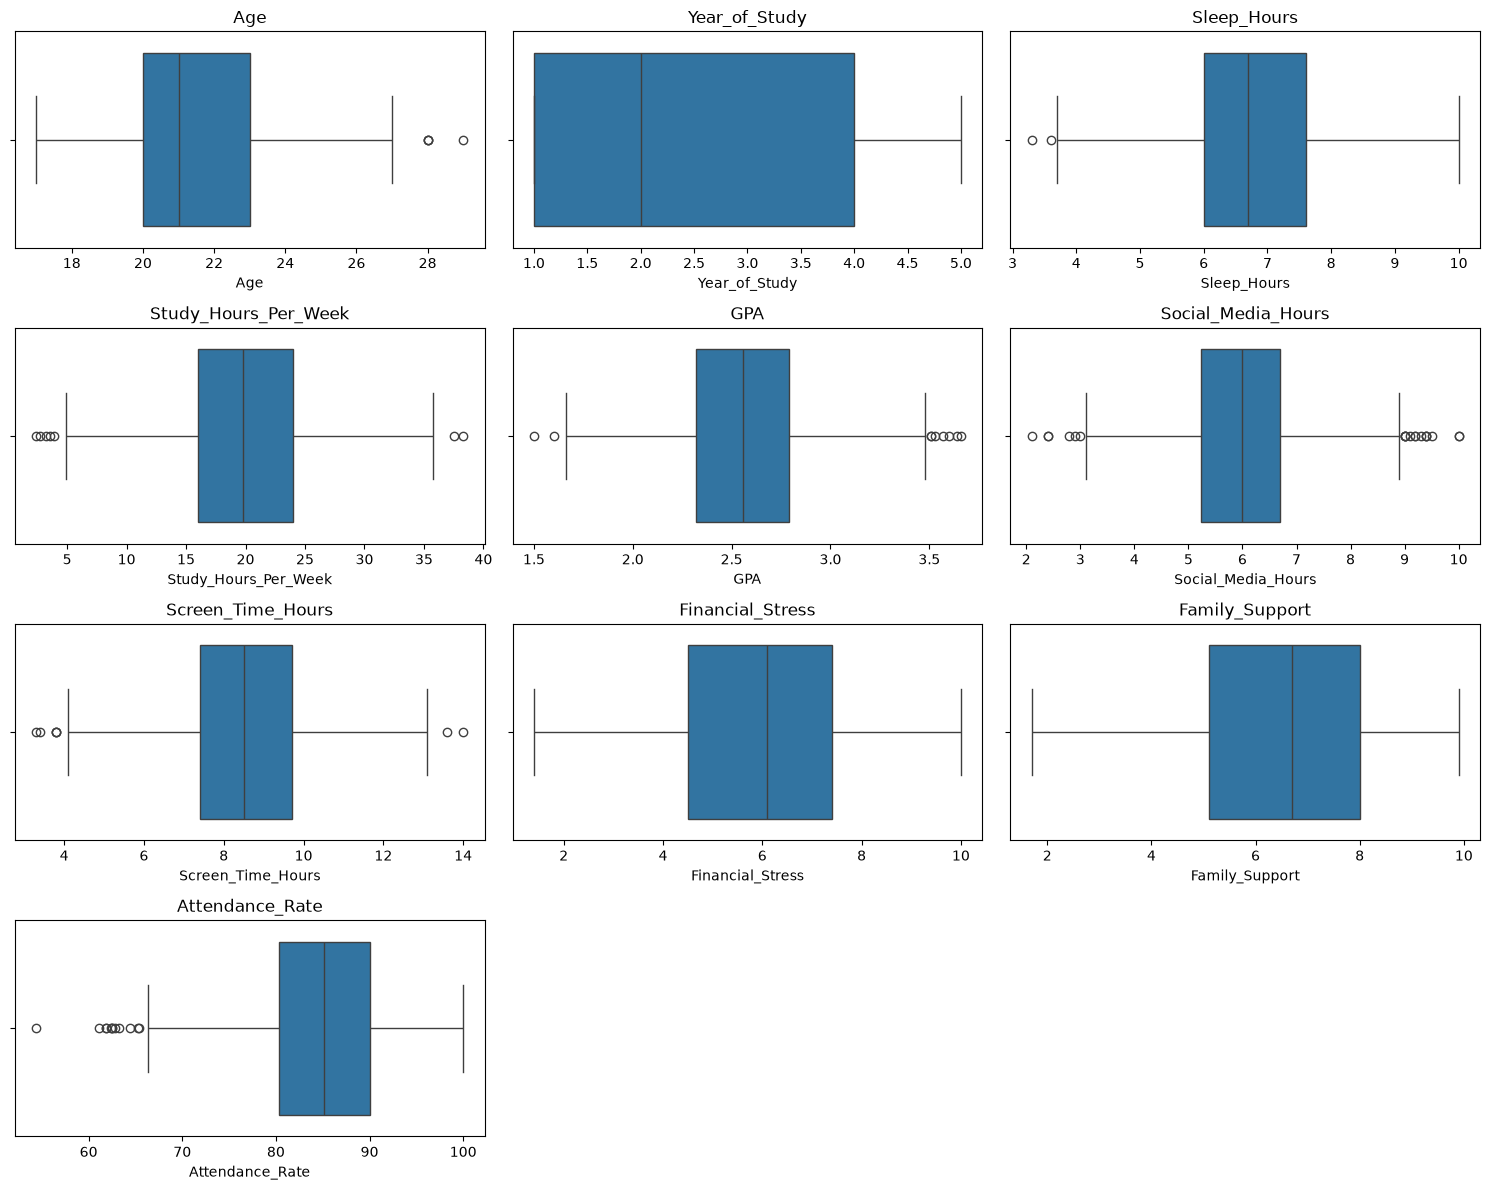

In [54]:
plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [55]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < borne_inf) | (df[col] > borne_sup)][col]
    print(f"{col} : {len(outliers)} outliers -> {outliers.values[:10]}")

Age : 4 outliers -> [29 28 28 28]
Year_of_Study : 0 outliers -> []
Sleep_Hours : 2 outliers -> [3.6 3.3]
Study_Hours_Per_Week : 7 outliers -> [ 3.9  3.2  3.6 38.3  2.4 37.5  2.7]
GPA : 9 outliers -> [3.6  1.5  3.66 3.53 3.64 3.57 3.51 1.6  3.51]
Social_Media_Hours : 20 outliers -> [ 2.4  9.   2.8  2.1  9.4  3.  10.   9.   2.9  9.1]
Screen_Time_Hours : 7 outliers -> [ 3.4  3.8  3.8  3.3  3.8 13.6 14. ]
Financial_Stress : 0 outliers -> []
Family_Support : 0 outliers -> []
Attendance_Rate : 12 outliers -> [61.1 62.4 62.5 62.8 62.5 63.2 65.4 65.3 54.4 61.8]


In [56]:
# 1. Vérifier les modalités des colonnes catégorielles (incohérences)
cat_cols = ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- Gender ---
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64
--- Physical_Activity ---
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64
--- Part_Time_Job ---
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64
--- Diet_Quality ---
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64
--- Previous_Mental_Health_History ---
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64


In [57]:
import pandas as pd

cat_cols = ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']

resume_cat = []
for col in cat_cols:
    counts = df[col].value_counts(dropna=False)
    for val, cnt in counts.items():
        resume_cat.append({
            'Colonne': col,
            'Catégorie': str(val),
            'Effectif': cnt,
            'Pourcentage (%)': round((cnt / len(df)) * 100, 2)
        })

df_resume_cat = pd.DataFrame(resume_cat)
display(df_resume_cat) # ou print(df_resume_cat.to_string(index=False))

,Colonne,Catégorie,Effectif,Pourcentage (%)
0,Gender,Female,971,48.55
1,Gender,Male,932,46.60
2,Gender,Non-binary,97,4.85
3,Physical_Activity,Moderate,906,45.30
4,Physical_Activity,Low,679,33.95
5,Physical_Activity,High,415,20.75
6,Part_Time_Job,No,1289,64.45
7,Part_Time_Job,Yes,711,35.55
8,Diet_Quality,Average,860,43.00
9,Diet_Quality,Poor,587,29.35


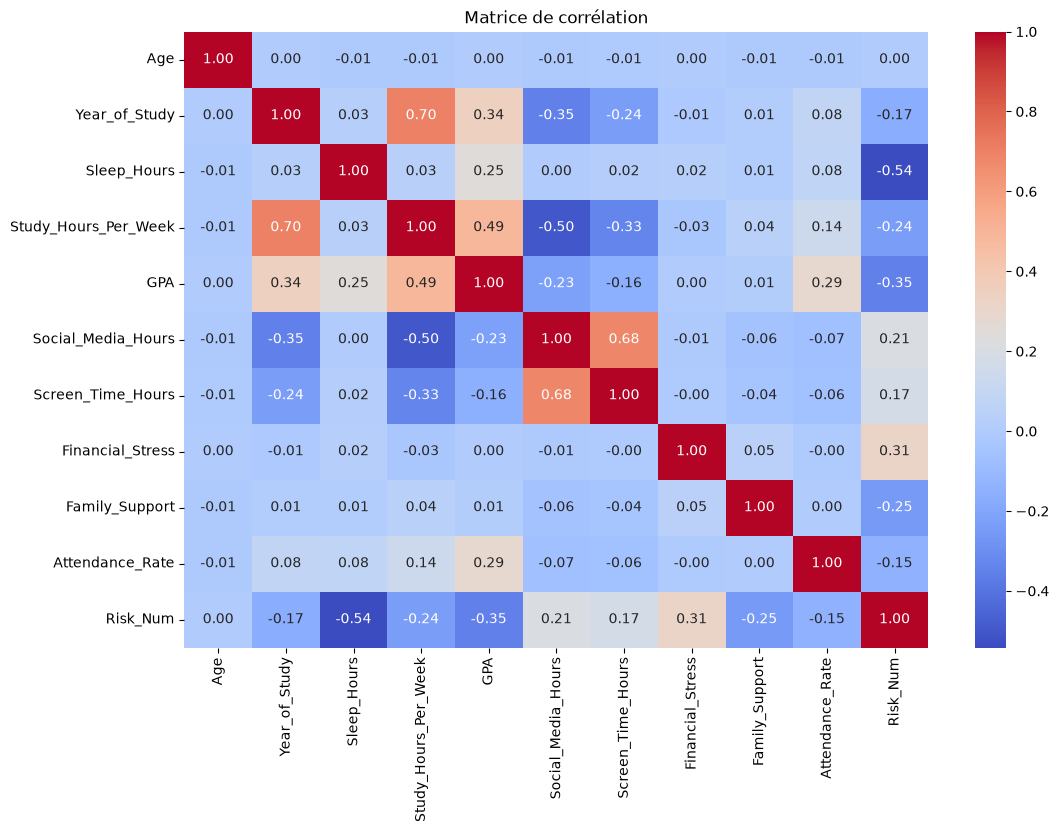

In [58]:
# 2. Matrice de corrélation (avec cible encodée temporairement pour l'analyse)
df_corr = df.copy()
df_corr['Risk_Num'] = df_corr['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})

plt.figure(figsize=(12, 8))
sns.heatmap(df_corr.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

In [ ]:
######################################################################################
##### Tâche 1.2 : Stratégie de Data Leakage Prevention (Split Train/Test 80/20)
######################################################################################

# 1. Séparer les variables explicatives (X) et la cible (y)
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"].map({'Low': 0, 'Medium': 1, 'High': 2})

# 2. Découper en Train (80%) et Test (20%) avec stratification sur la cible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Définir la fonction de Feature Engineering (création des 3 nouvelles variables)
def add_features(df_in):
    df_out = df_in.copy()
    df_out['Social_Media_Ratio'] = df_out['Social_Media_Hours'] / df_out['Screen_Time_Hours']
    df_out['Study_Sleep_Ratio'] = df_out['Study_Hours_Per_Week'] / (df_out['Sleep_Hours'] * 7)
    df_out['Stress_Support_Balance'] = df_out['Financial_Stress'] - df_out['Family_Support']
    return df_out

# 4. Regrouper les colonnes par catégorie de traitement
num_cols = ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
            'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

ord_cols = ['Physical_Activity', 'Diet_Quality']
ord_categories = [['Low', 'Moderate', 'High'], ['Poor', 'Average', 'Good']]

nom_cols = ['Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']

# 5. Sous-pipeline Numérique : 1) Imputation -> 2) Feature Engineering -> 3) Scaling
# set_output(transform="pandas") permet de garder les noms de colonnes pour add_features
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median").set_output(transform="pandas")),
    ("features", FunctionTransformer(add_features)),
    ("scaler", StandardScaler())
])

# 6. Sous-pipeline Catégoriel Ordinal : 1) Imputation -> 2) Encodage avec ordre
ord_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("ordinal", OrdinalEncoder(categories=ord_categories))
])

# 7. Sous-pipeline Catégoriel Nominal : 1) Imputation -> 2) Encodage binaire (One-Hot)
nom_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop='first', sparse_output=False)) 
])

# 8. Assemblage final dans ColumnTansformer
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("ord", ord_pipeline, ord_cols),
    ("nom", nom_pipeline, nom_cols),
])

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (1600, 15) | Test shape: (400, 15)


In [60]:
######################################################################################
##### Étape 3 : Entraînement et Comparaison des Modèles
######################################################################################

# 1. Définir les 3 modèles à tester
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100,learning_rate=0.1,max_depth=4,random_state=42,eval_metric="mlogloss")
}

results = []

# 2. Entraîner et évaluer chaque modèle dans un Pipeline complet
for name, model in models.items():
    full_pipline = Pipeline([
        ("preprocesso", preprocessor), 
        ("model", model)
    ])

    # Entraînement sur le Train (80%)
    full_pipline.fit(X_train, y_train)

    # Prédiction sur le Test (20%)
    y_pred = full_pipline.predict(X_test)
    
    # Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")

    results.append({
        "Modèle": name,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4)
    })

# 3. Afficher le tableau comparatif classé par F1-Score
df_results = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_results)
    


,Modèle,Accuracy,F1-Score
0,Logistic Regression,0.7700,0.7712
1,Gradient Boosting,0.7025,0.7005
2,XGBoost,0.7000,0.6959
3,Random Forest,0.6825,0.6797



================ Logistic Regression (ROC-AUC : 0.9180) ================
              precision    recall  f1-score   support

     Low (0)       0.83      0.78      0.80       132
  Medium (1)       0.65      0.68      0.66       132
    High (2)       0.84      0.85      0.84       136

    accuracy                           0.77       400
   macro avg       0.77      0.77      0.77       400
weighted avg       0.77      0.77      0.77       400


================ Random Forest (ROC-AUC : 0.8692) ================
              precision    recall  f1-score   support

     Low (0)       0.71      0.73      0.72       132
  Medium (1)       0.56      0.52      0.54       132
    High (2)       0.77      0.80      0.78       136

    accuracy                           0.68       400
   macro avg       0.68      0.68      0.68       400
weighted avg       0.68      0.68      0.68       400


================ Gradient Boosting (ROC-AUC : 0.8696) ================
              precision 

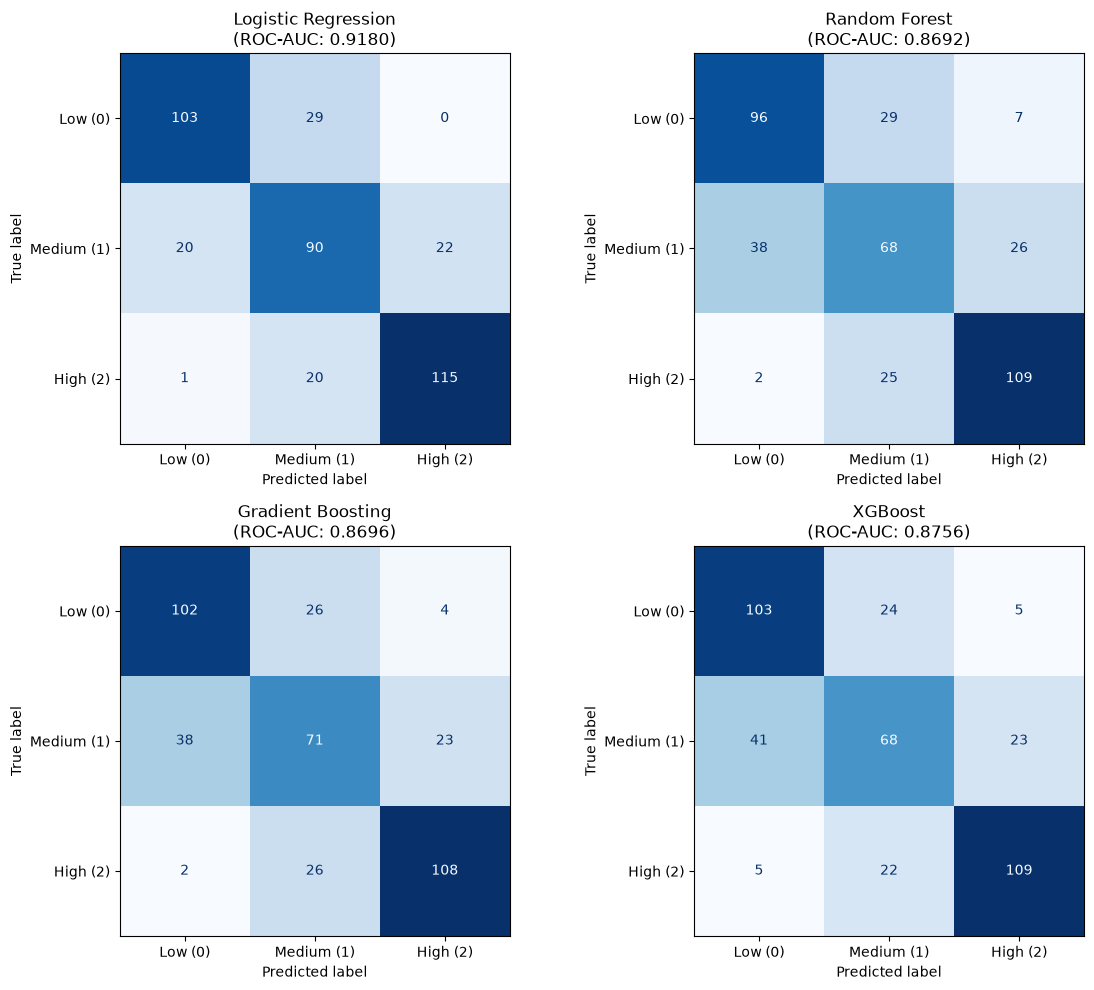

In [61]:
######################################################################################
##### Étape 4 : Évaluation détaillée de tous les modèles (Rapports + ROC-AUC + Matrices)
######################################################################################

target_names = ['Low (0)', 'Medium (1)', 'High (2)']

# Créer une grille de 2 lignes x 2 colonnes pour afficher les 4 matrices ensemble
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    # 1. Entraîner le pipeline pour ce modèle
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    
    # Prédictions de classes et de probabilités (nécessaires pour ROC-AUC)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    
    # 2. Calculer le score ROC-AUC multi-classes
    auc_score = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')
    
    # 3. Afficher le rapport de classification et le ROC-AUC
    print(f"\n================ {name} (ROC-AUC : {auc_score:.4f}) ================")
    print(classification_report(y_test, y_pred, target_names=target_names))
    
    # 4. Tracer la matrice de confusion dans la case correspondante
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=target_names, cmap='Blues', ax=axes[idx], colorbar=False
    )
    axes[idx].set_title(f"{name}\n(ROC-AUC: {auc_score:.4f})")

plt.tight_layout()
plt.show()

In [62]:
######################################################################################
##### Tâche 2.2 : Optimisation des Hyperparamètres (GridSearchCV)
######################################################################################


# 1. Définir les modèles et leurs grilles de paramètres
grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {"model__C": [0.01, 0.1, 1, 10, 100], "model__solver": ["lbfgs", "saga"]}
    ),
    "XGBoost": (
        XGBClassifier(random_state=42, eval_metric="mlogloss"),
        {"model__n_estimators": [100, 200], "model__max_depth": [3, 4, 6], "model__learning_rate": [0.05, 0.1]}
    )
}

best_models = {}

# 2. Lancer la recherche par validation croisée (cv=5)
for name, (model, params) in grids.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    
    search = GridSearchCV(pipe, params, cv=5, scoring="f1_weighted", n_jobs=-1)
    search.fit(X_train, y_train)
    
    best_models[name] = search.best_estimator_
    print(f"--- {name} ---")
    print("Meilleurs paramètres :", search.best_params_)
    print(f"Meilleur F1 (CV)     : {search.best_score_:.4f}\n")

--- Logistic Regression ---
Meilleurs paramètres : {'model__C': 100, 'model__solver': 'lbfgs'}
Meilleur F1 (CV)     : 0.7593

--- XGBoost ---
Meilleurs paramètres : {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 100}
Meilleur F1 (CV)     : 0.7193



In [63]:
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"{name} (Optimisé sur Test) -> F1-Score : {f1:.4f}")

Logistic Regression (Optimisé sur Test) -> F1-Score : 0.7689
XGBoost (Optimisé sur Test) -> F1-Score : 0.6959


In [ ]:
######################################################################################
##### Tâches 2.3 & 2.4 : Évaluation Finale sur Test Set & Export du Pipeline
######################################################################################

# 1. Récupérer le meilleur modèle optimisé
final_model = best_models["Logistic Regression"]

# 2. Évaluer sur le jeu de Test (20%)
y_pred_final = final_model.predict(X_test)
y_proba_final = final_model.predict_proba(X_test)

print(f"F1-Score Final (Test) : {f1_score(y_test, y_pred_final, average='weighted'):.4f}")
print(f"ROC-AUC Final (Test)  : {roc_auc_score(y_test, y_proba_final, multi_class='ovr', average='weighted'):.4f}\n")
print(classification_report(y_test, y_pred_final, target_names=['Low (0)', 'Medium (1)', 'High (2)']))

# 3. Sauvegarder le pipeline complet (prétraitement + modèle)
joblib.dump(final_model, "mental_health_pipeline.joblib")
print("Pipeline sauvegardé sous : mental_health_pipeline.joblib")

# 4. Vérification rapide du fichier sauvegardé
loaded_model = joblib.load("mental_health_pipeline.joblib")
print("Prédictions du modèle :", loaded_model.predict(X_test.iloc[:3]))
print("Vraies valeurs (y_test) :", y_test.iloc[:3].values)

F1-Score Final (Test) : 0.7689
ROC-AUC Final (Test)  : 0.9183

              precision    recall  f1-score   support

     Low (0)       0.83      0.78      0.80       132
  Medium (1)       0.64      0.68      0.66       132
    High (2)       0.84      0.84      0.84       136

    accuracy                           0.77       400
   macro avg       0.77      0.77      0.77       400
weighted avg       0.77      0.77      0.77       400

Pipeline sauvegardé sous : mental_health_pipeline.joblib
Prédictions du modèle : [1 0 0]
Vraies valeurs (y_test) : [1 0 0]
